### what is LLM
Large Language Model (LLM) là một mạng neural sâu (deep neural network) được thiết kế để hiểu, tạo ra và phản hồi văn bản giống ngôn ngữ con người.
Tác giả nhấn mạnh chữ Large có hai ý nghĩa:
- Model size: Mô hình có rất nhiều parameters (tham số), có thể lên đến hàng chục hoặc hàng trăm tỷ.
- Training dataset: Mô hình được huấn luyện trên lượng dữ liệu văn bản khổng lồ.
Các parameters chính là những trọng số có thể điều chỉnh trong quá trình huấn luyện.
LLM có khả năng thực hiện nhiều nhiệm vụ như text generation, translation, summarization và classification.  
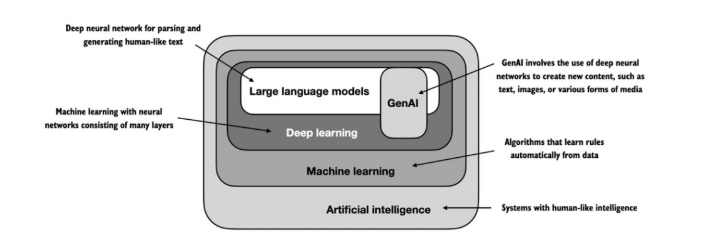 

### Next-token prediction — Dự đoán token tiếp theo  
nhiệm vụ pretraining cốt lõi của GPT là next-word prediction. Khi triển khai thực tế với tokenizer, model dự đoán token tiếp theo, mà token không nhất thiết là một từ hoàn chỉnh.  

Self-supervised learning: Không cần con người gán nhãn thủ công cho từng ví dụ. Phần tiếp theo của văn bản được dùng làm nhãn huấn luyện.
Autoregressive model: Model sử dụng chuỗi token đã có, bao gồm các token vừa sinh ra, để dự đoán token tiếp theo.
Ví dụ với chuỗi token ["I", "love", "machine", "learning"]: 

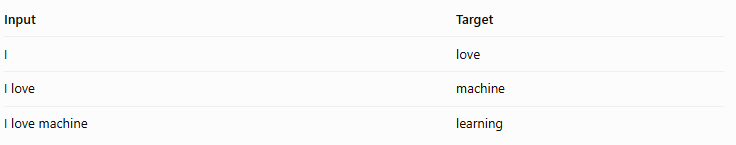  

Mô hình học dự đoán target từ input. Trong quá trình huấn luyện, các dự đoán được so sánh với token thực tế để tối ưu trọng số.
Điểm cần nhớ: GPT không tạo toàn bộ câu trong một lần dự đoán. Nó sinh từng token liên tiếp dựa trên ngữ cảnh trước đó. 

### 3. Text preprocessing — Tiền xử lý văn bản
Theo sách, LLM không thể trực tiếp xử lý văn bản thô bằng các phép toán của neural network. Vì vậy, dữ liệu văn bản cần được chuẩn bị trước khi đưa vào model.  

### Tokenization — Tách văn bản thành token
Chapter 2 — Sections 2.2, 2.5
Tokenization là quá trình chia văn bản thành các đơn vị nhỏ hơn gọi là tokens.
- có 2 cái thứ nhất là Simple tokenization: chia theo các loại dấu câu
- Byte Pair Encoding (BPE)  Biểu diễn văn bản bằng token ở mức từ, từ con hoặc đơn vị nhỏ hơn
- BPE xây dựng vocabulary bằng cách lặp lại việc gộp các cặp đơn vị xuất hiện thường xuyên, từ các đơn vị nhỏ thành các subword lớn hơn.
Ưu điểm quan trọng là có thể xử lý từ không xuất hiện nguyên vẹn trong vocabulary bằng cách chia thành những phần nhỏ hơn.
 
 Cần nhớ: Một token có thể là một từ, một phần của từ hoặc ký hiệu. Không được mặc định rằng một token luôn bằng một từ.

### Token IDs — Mã định danh của token
Sau khi tách văn bản thành tokens, mỗi token được ánh xạ đến một số nguyên duy nhất trong vocabulary.
ví dụ
[15496, 11, 466, 345, 588, 8887, 30]
Hello, do you like tea?

Sách giới thiệu hai phương thức:
- encode(): Text → Tokens → Token IDs. -> BERT
- decode(): Token IDs → Tokens → Text. -> GPT (Generative Pre-trained Transformer)
Token ID chỉ là mã định danh, không phải giá trị biểu diễn ngữ nghĩa của từ. Việc tạo biểu diễn số liên tục sẽ do embedding layer đảm nhiệm.

### Context window — Cửa sổ ngữ cảnh
- Trong phần này, sách sử dụng các thuật ngữ context_size, context_length và max_length để mô tả số token trong một đoạn đầu vào dùng cho huấn luyện.   
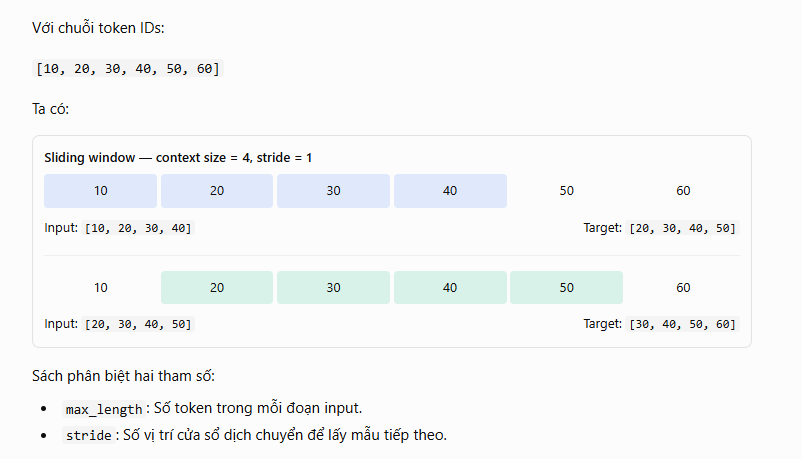  


Ví dụ max_length=4, stride=4 sẽ tạo các đoạn không chồng lấn nhau.  
Điểm cần nhớ: Context length quyết định độ dài chuỗi input trong ví dụ huấn luyện. Sliding window giúp tạo nhiều cặp input-target từ cùng một văn bản.

### Token embeddings — Biểu diễn token thành vector 

- Theo sách, embedding là phép ánh xạ các đối tượng rời rạc, như token, vào không gian vector liên tục để neural network có thể xử lý.  
- 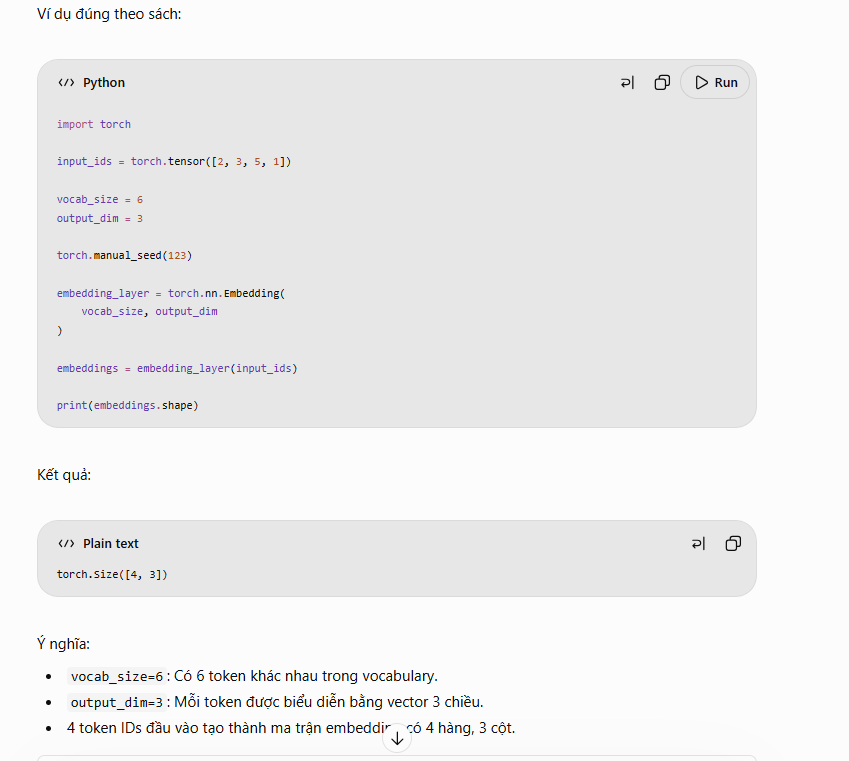  
- Ý nghĩa:
- vocab_size=6: Có 6 token khác nhau trong vocabulary.
- output_dim=3: Mỗi token được biểu diễn bằng vector 3 chiều.
- 4 token IDs đầu vào tạo thành ma trận embedding có 4 hàng, 3 cột.
  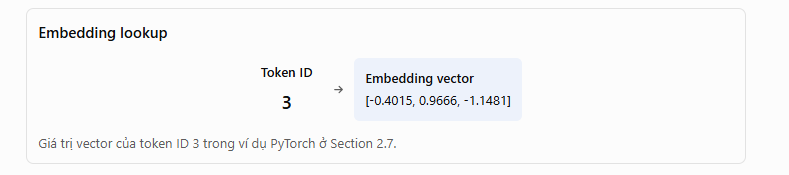
**Sách nhấn mạnh embedding layer thực chất thực hiện một lookup operation: lấy hàng tương ứng với token ID từ ma trận trọng số embedding.
Các trọng số này ban đầu được khởi tạo ngẫu nhiên và được tối ưu trong quá trình huấn luyện LLM.
Đây cũng là điểm khác biệt với việc sử dụng một mô hình Word2Vec đã huấn luyện sẵn: embedding của LLM được học cùng với chính LLM đó**  

### Positional embeddings — Biểu diễn vị trí token
Vấn đề được tác giả đặt ra là: Token embedding không tự chứa thông tin về vị trí của token trong chuỗi.
Cùng một token ID sẽ cho cùng một embedding vector dù xuất hiện ở vị trí thứ nhất hay thứ ba.  
Trong khi đó, thứ tự token rất quan trọng để hiểu ngôn ngữ.  
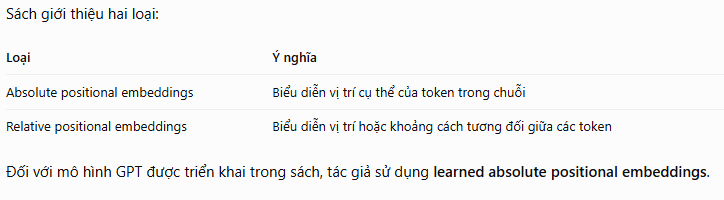  
Công thức ý tưởng:
$$
\text{Input Embedding} =
\text{Token Embedding} +
\text{Positional Embedding}
$$  

Điểm cần nhớ: Token embeddings biểu diễn token, còn positional embeddings bổ sung thông tin về vị trí để model xử lý thứ tự trong chuỗi.